In [ ]:
# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ot import sliced_wasserstein_distance
from scipy.stats import energy_distance
from cluster_weather_years.constants import BASE_OUTPUT

In [ ]:
NUM_DRAWS = int(1e5)  # number of random draws to compare with
NUM_CLUSTERS = 30  # number of Climate Years to select
ALL_MATCH_COUNTRIES = ["NL"]

In [ ]:
df_wass_scores = pd.read_csv(
    f"{BASE_OUTPUT}/metrics_random_draws/wasserstein_{ALL_MATCH_COUNTRIES}_{NUM_DRAWS}_draws_{NUM_CLUSTERS}_clusters.csv",
    index_col=0,
)

df_score_all_good = pd.read_csv(
    f"{BASE_OUTPUT}/metrics_random_draws/univariate_scores_{ALL_MATCH_COUNTRIES}_{NUM_DRAWS}_draws_{NUM_CLUSTERS}_clusters.csv",
    index_col=0,
)

In [ ]:
# find worst variable per dataset, based on QQ-MAE
idx = df_score_all_good.groupby("ds_name")["qq_mae"].idxmax()
df_worst = df_score_all_good.loc[idx].reset_index(drop=True)

df_worst = df_worst.sort_values("qq_mae").rename(
    columns={"variable": "bottleneck_variable"}
)
df_worst = df_worst.merge(df_wass_scores, on="ds_name").sort_values("Wasserstein")
df_worst["ds_type"] = df_worst["ds_name"].apply(
    lambda x: "Optimized" if not x.startswith("Random") else "Random"
)

# rank datasets based on all metrics
df_ranked = df_worst.copy()
for metric in df_worst.columns[2:-1]:
    df_ranked[metric] = df_ranked[metric].rank()

df_ranked["total_rank"] = df_ranked[df_ranked.columns[2:-1]].sum(axis=1)
df_ranked = df_ranked.sort_values("total_rank")

In [ ]:
# shows dataset that is 'least bad' on top
df_worst.sort_values("qq_mae")

,ds_name,bottleneck_variable,d_mean,energy_distance_score,qq_mae,qq_mae_low,qq_mae_high,Wasserstein,ds_type
0,Multi-country 7,NL_OFF_prod,0.000662,0.103162,1.275501,1.154260,1.314143,1.933029,Optimized
1,Random_N 98359,NL_OFF_prod,0.000249,0.118349,1.368142,0.777831,0.474886,2.177010,Random
2,Random_N 91845,NL_SOLAR_prod,0.001969,0.133664,1.385536,0.473043,2.406441,2.047925,Random
3,Random_N 71687,NL_OFF_prod,0.001102,0.121820,1.392283,0.826361,0.680653,2.178120,Random
4,Multi-country 4,NL_SOLAR_prod,0.002149,0.129507,1.428304,0.722727,1.932977,1.830103,Optimized
...,...,...,...,...,...,...,...,...,...
510,Random_N 4063,NL_SOLAR_prod,0.007104,0.192515,2.521839,2.008927,7.076043,2.347564,Random
511,Random_N 40648,NL_OFF_prod,0.004591,0.198436,2.552296,1.687735,1.043629,2.460140,Random
512,Random_N 37357,NL_OFF_prod,0.003971,0.191375,2.560278,2.839501,1.995702,2.385656,Random
513,Random_N 65861,NL_SOLAR_prod,0.001040,0.199199,2.613483,2.464741,9.155593,2.653330,Random


In [ ]:
# shows dataset that is 'best' on top
df_wass_scores.sort_values("Wasserstein")

,ds_name,Wasserstein
0,Multi-country 1,1.597116
4,Multi-country 5,1.697542
1,Multi-country 2,1.711521
303,Random_N 56559,1.793407
2,Multi-country 3,1.808818
...,...,...
233,Random_N 41142,3.469677
237,Random_N 41438,3.497663
270,Random_N 48974,3.513036
421,Random_N 82382,3.718719


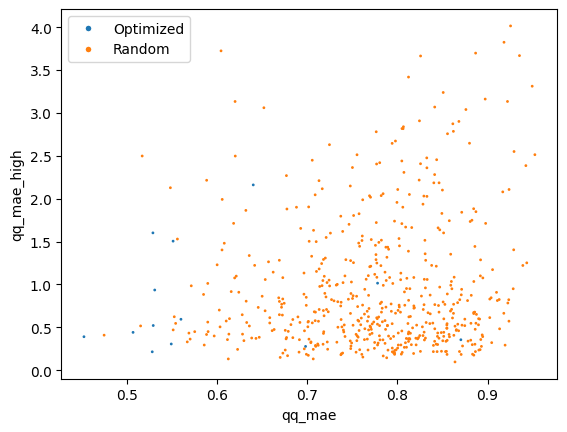

In [ ]:
metric_1 = "qq_mae"
metric_2 = "qq_mae_high"

plt.figure()
plt.scatter(
    df_worst[metric_1],
    df_worst[metric_2],
    c=df_worst["ds_type"].map({"Optimized": "C0", "Random": "C1"}),
    s=1,
)
plt.xlabel(metric_1)
plt.ylabel(metric_2)
plt.legend(
    handles=[
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label="Optimized",
            markerfacecolor="C0",
            markersize=5,
        ),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label="Random",
            markerfacecolor="C1",
            markersize=5,
        ),
    ]
)